# Facebook Ad Campaign Analysis: Where the Budget Should Go

**Data:** [Sales Conversion Optimization (Kaggle)](https://www.kaggle.com/datasets/loveall/clicks-conversion-tracking): 1,143 Facebook ads across 3 campaigns, with impressions, clicks, spend, leads (`Total_Conversion`) and sales (`Approved_Conversion`).

**Question:** Which campaigns and audiences turn ad spend into sales most efficiently, and where should budget move?

**Method:** All cleaning and metrics are in SQL (DuckDB), in `sql/`. This notebook runs those files and makes the charts.

**Assumption:** There is no revenue column, so ROAS assumes **$100 of revenue per sale**. CPA, which needs no assumption, is the primary metric.

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import os
os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())

con = duckdb.connect()
def run(path):
    # DuckDB runs every statement in the file and returns the last SELECT's result
    r = con.sql(open(path).read())
    return r.df() if r is not None else None

pd.set_option('display.width', 200)

## 1. Clean
No nulls and no duplicate `ad_id`s. One pair of rows is identical apart from `ad_id`; both are kept because they are separate ads. There is no date column, so there are no date formats to fix and no day-of-week cut is possible. 207 ads have $0 spend but still report conversions, probably from view-through attribution. They stay in the totals and are flagged as `is_unpaid`.

In [2]:
run('sql/01_clean.sql')
con.sql('''SELECT COUNT(*) rows, COUNT(DISTINCT ad_id) unique_ads,
           COUNT(*) FILTER (WHERE is_unpaid) zero_spend_ads FROM ads''').df()

,rows,unique_ads,zero_spend_ads
0,1143,1143,207


## 2. Core metrics

In [3]:
seg = run('sql/02_metrics.sql')
overall = con.sql('''SELECT ROUND(SUM(spend),2) spend, SUM(impressions) impressions, SUM(clicks) clicks,
    SUM(leads) leads, SUM(sales) sales,
    ROUND(100.0*SUM(clicks)/SUM(impressions),4) ctr_pct,
    ROUND(100.0*SUM(leads)/SUM(clicks),2) lead_cvr_pct,
    ROUND(SUM(spend)/SUM(sales),2) cpa,
    ROUND(SUM(sales)*100/SUM(spend),2) roas FROM ads''').df()
overall

,spend,impressions,clicks,leads,sales,ctr_pct,lead_cvr_pct,cpa,roas
0,58705.23,213434828.0,38165.0,3264.0,1079.0,0.0179,8.55,54.41,1.84


In [4]:
cols = ['segment','ads','spend','spend_share_pct','sales_share_pct','ctr_pct','lead_cvr_pct','approval_rate_pct','cpa','roas']
for d in ['campaign','age_group','gender']:
    print(f'\n=== {d} ===')
    print(seg[seg.dimension==d][cols].sort_values('segment').to_string(index=False))


=== campaign ===
   segment  ads    spend  spend_share_pct  sales_share_pct  ctr_pct  lead_cvr_pct  approval_rate_pct   cpa  roas
Campaign A   54   149.71              0.3              2.2   0.0234         51.33               41.4  6.24 16.03
Campaign B  464  2893.37              4.9             17.0   0.0244         27.07               34.1 15.81  6.32
Campaign C  625 55662.15             94.8             80.8   0.0176          7.40               32.7 63.83  1.57

=== age_group ===
segment  ads    spend  spend_share_pct  sales_share_pct  ctr_pct  lead_cvr_pct  approval_rate_pct   cpa  roas
  30-34  426 15252.40             26.0             45.8   0.0139         15.09               34.5 30.88  3.24
  35-39  248 11112.43             18.9             19.2   0.0168          8.82               33.1 53.68  1.86
  40-44  210 11589.73             19.7             15.8   0.0195          6.76               32.5 68.17  1.47
  45-49  259 20750.67             35.3             19.3   0.0217       

## 3. Segments

In [5]:
run('sql/03_segments.sql')
grid = con.sql('SELECT * FROM c_age_gender').df()
grid

,gender,age_group,spend,pct_of_total_spend,sales,cpa
0,Female,30-34,7309.56,12.5,152.0,48.09
1,Female,35-39,5737.94,9.8,72.0,79.69
2,Female,40-44,7019.74,12.0,80.0,87.75
3,Female,45-49,11985.17,20.4,87.0,137.76
4,Male,30-34,7476.07,12.7,243.0,30.77
5,Male,35-39,4967.42,8.5,95.0,52.29
6,Male,40-44,4102.78,7.0,61.0,67.26
7,Male,45-49,7063.47,12.0,82.0,86.14


## 4. Charts

In [6]:
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#b8b7b2'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.edgecolor':'#d6d5d0',
    'axes.labelcolor':INK2,'xtick.color':INK2,'ytick.color':INK2,'axes.spines.top':False,
    'axes.spines.right':False,'figure.dpi':150,'savefig.bbox':'tight','figure.facecolor':'white'})
Path('charts').mkdir(exist_ok=True)
def title(ax, t, sub):
    ax.set_title(t, loc='left', fontsize=13, fontweight='bold', color=INK, pad=22)
    ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=10, color=INK2)

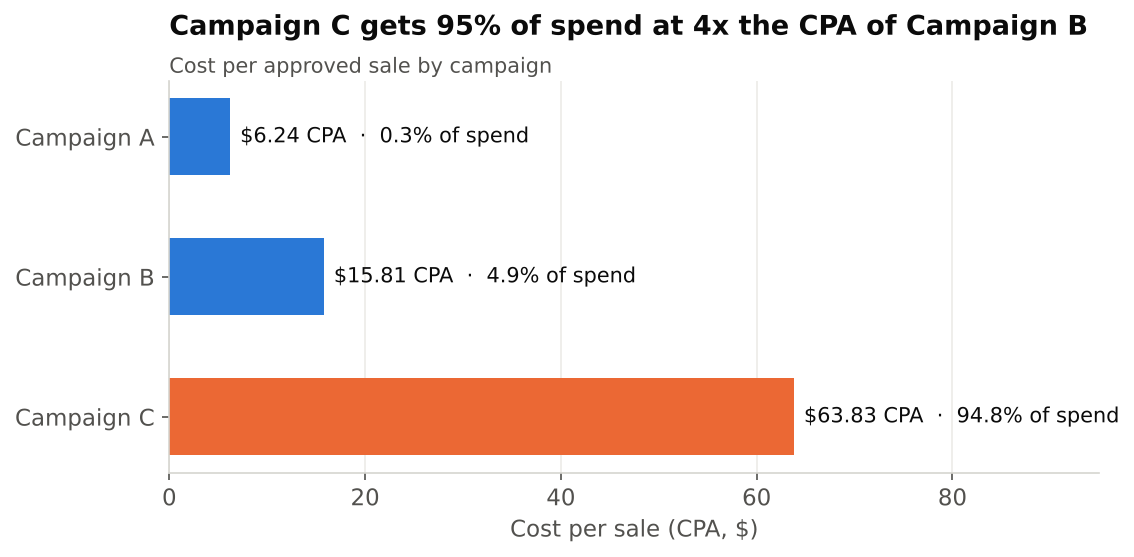

In [7]:
# Chart 1: CPA by campaign, labelled with spend share
c = seg[seg.dimension=='campaign'].sort_values('segment', ascending=False)
fig, ax = plt.subplots(figsize=(8,3.4))
colors = [ORANGE if s=='Campaign C' else BLUE for s in c.segment]
ax.barh(c.segment, c.cpa, color=colors, height=0.55)
for y,(cpa,sh) in enumerate(zip(c.cpa, c.spend_share_pct)):
    ax.text(cpa+1, y, f'${cpa:.2f} CPA  ·  {sh:.1f}% of spend', va='center', fontsize=10, color=INK)
ax.set_xlim(0, 95); ax.set_xlabel('Cost per sale (CPA, $)')
ax.xaxis.grid(True, color='#ecebe7'); ax.set_axisbelow(True)
title(ax, 'Campaign C gets 95% of spend at 4x the CPA of Campaign B', 'Cost per approved sale by campaign')
fig.savefig('charts/1_cpa_by_campaign.png'); plt.show()

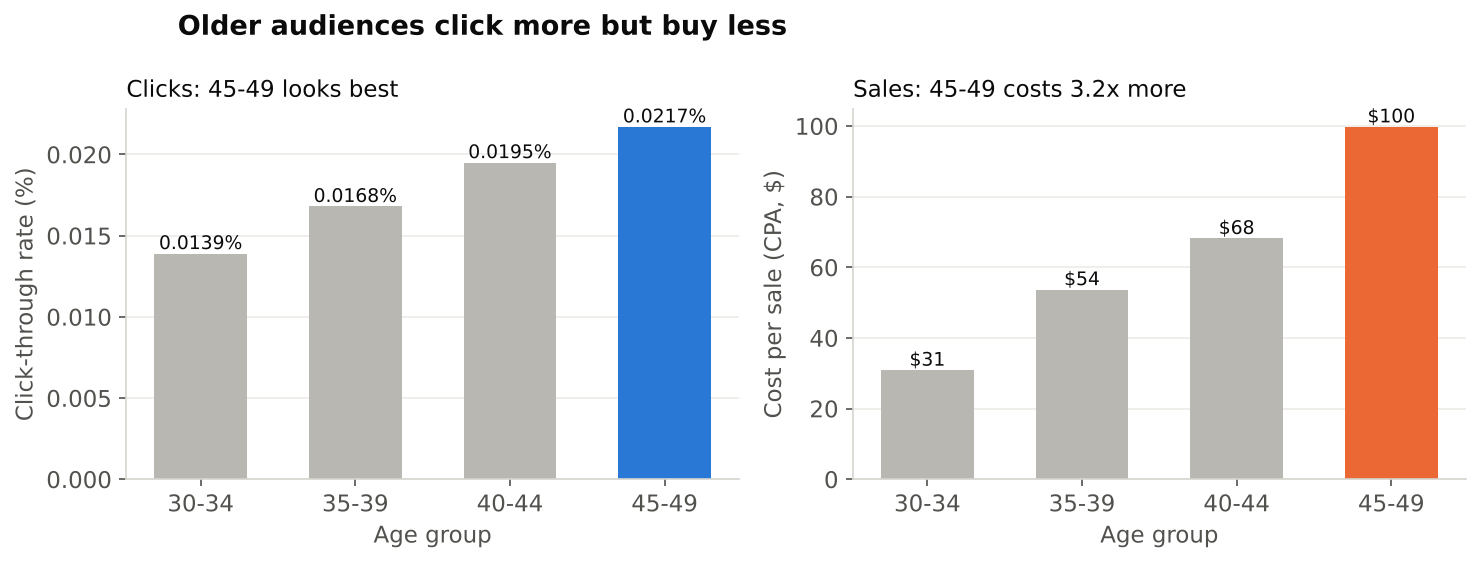

In [8]:
# Chart 2: the CTR trap. CTR and CPA by age, as two panels (not a dual axis)
a = seg[seg.dimension=='age_group'].sort_values('segment')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,3.8))
ax1.bar(a.segment, a.ctr_pct, color=GRAY, width=0.6)
ax1.bar(a.segment.iloc[-1:], a.ctr_pct.iloc[-1:], color=BLUE, width=0.6)
for x,v in enumerate(a.ctr_pct): ax1.text(x, v, f'{v:.4f}%', ha='center', va='bottom', fontsize=9, color=INK)
ax1.set_ylabel('Click-through rate (%)'); ax1.set_xlabel('Age group')
ax2.bar(a.segment, a.cpa, color=GRAY, width=0.6)
ax2.bar(a.segment.iloc[-1:], a.cpa.iloc[-1:], color=ORANGE, width=0.6)
for x,v in enumerate(a.cpa): ax2.text(x, v, f'${v:.0f}', ha='center', va='bottom', fontsize=9, color=INK)
ax2.set_ylabel('Cost per sale (CPA, $)'); ax2.set_xlabel('Age group')
for ax in (ax1, ax2): ax.yaxis.grid(True, color='#ecebe7'); ax.set_axisbelow(True)
ax1.set_title('Clicks: 45-49 looks best', loc='left', fontsize=11, color=INK)
ax2.set_title('Sales: 45-49 costs 3.2x more', loc='left', fontsize=11, color=INK)
fig.suptitle('Older audiences click more but buy less', x=0.125, ha='left', fontsize=13, fontweight='bold', color=INK)
fig.tight_layout(); fig.savefig('charts/2_ctr_vs_cpa_by_age.png'); plt.show()

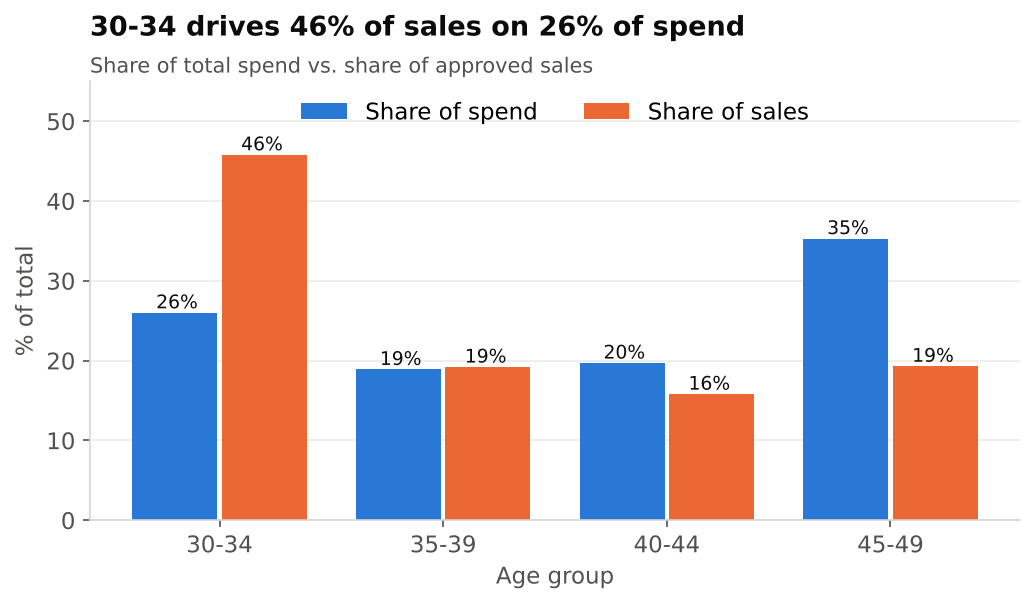

In [9]:
# Chart 3: spend share vs sales share by age
import numpy as np
x = np.arange(len(a)); w = 0.38
fig, ax = plt.subplots(figsize=(8,3.8))
ax.bar(x-w/2-0.01, a.spend_share_pct, w, color=BLUE, label='Share of spend')
ax.bar(x+w/2+0.01, a.sales_share_pct, w, color=ORANGE, label='Share of sales')
for i,(s,v) in enumerate(zip(a.spend_share_pct, a.sales_share_pct)):
    ax.text(i-w/2, s, f'{s:.0f}%', ha='center', va='bottom', fontsize=9, color=INK)
    ax.text(i+w/2, v, f'{v:.0f}%', ha='center', va='bottom', fontsize=9, color=INK)
ax.set_xticks(x, a.segment); ax.set_xlabel('Age group'); ax.set_ylabel('% of total')
ax.yaxis.grid(True, color='#ecebe7'); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.0))
ax.set_ylim(0, 55)
title(ax, '30-34 drives 46% of sales on 26% of spend', 'Share of total spend vs. share of approved sales')
fig.savefig('charts/3_spend_vs_sales_share_by_age.png'); plt.show()

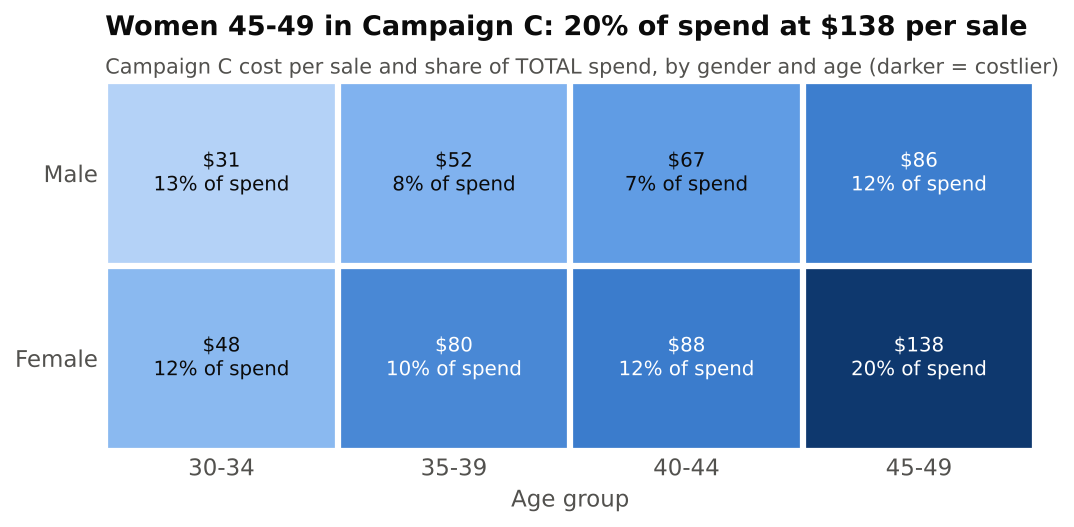

In [10]:
# Chart 4: CPA heatmap, Campaign C, gender x age (sequential, one hue)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('blue', ['#cde2fb','#6da7ec','#256abf','#0d366b'])
pv = grid.pivot(index='gender', columns='age_group', values='cpa').loc[['Male','Female']]
sp = grid.pivot(index='gender', columns='age_group', values='pct_of_total_spend').loc[['Male','Female']]
fig, ax = plt.subplots(figsize=(8,3.2))
im = ax.imshow(pv.values, cmap=cmap, aspect='auto', vmin=20, vmax=140)
ax.set_xticks(range(4), pv.columns); ax.set_yticks(range(2), pv.index)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
for i in range(2):
    for j in range(4):
        v = pv.values[i,j]
        ax.text(j, i, f'${v:.0f}\n{sp.values[i,j]:.0f}% of spend', ha='center', va='center',
                fontsize=9.5, color='white' if v > 70 else INK)
ax.set_xticks(np.arange(-.5,4,1), minor=True); ax.set_yticks(np.arange(-.5,2,1), minor=True)
ax.grid(which='minor', color='white', linewidth=3); ax.tick_params(which='minor', length=0)
ax.set_xlabel('Age group')
title(ax, 'Women 45-49 in Campaign C: 20% of spend at $138 per sale', 'Campaign C cost per sale and share of TOTAL spend, by gender and age (darker = costlier)')
fig.savefig('charts/4_campaign_c_cpa_heatmap.png'); plt.show()

## 5. Insights

**1. Budget is concentrated in the least efficient campaign.** Campaign C takes 94.8% of spend ($55.7k) at a $63.83 CPA, 4.0x Campaign B's $15.81. *Action:* move 10% of C's budget (about $5.6k) into B in two or three steps over a few weeks, and keep going only while B's marginal CPA stays under about $40. B has only spent $2.9k so far, so its CPA is likely to rise as it scales.

**2. CTR rewards the wrong audience.** Ages 45-49 have the highest CTR (0.0217% vs 0.0139% for 30-34) and the biggest share of spend (35%), but a $99.76 CPA, 3.2x the $30.88 for 30-34. The same ordering shows up in Campaigns B and C and for both genders. *Action:* move $5k from 45-49 to 30-34. At average CPAs that is roughly +112 sales; treat that as an upper bound, because marginal CPA rises with scale.

**3. Female 45-49 in Campaign C is the most expensive cell.** It takes 20.4% of all spend ($12.0k) at $137.76 per sale, 4.5x men 30-34 in the same campaign ($30.77). At the assumed $100 sale value it loses money (ROAS 0.73). *Action:* cut this cell's budget by half, switch the campaign's optimisation goal from clicks to conversions, and move the freed budget to 30-34.

## Limitations
- No revenue column, so ROAS depends on the $100-per-sale assumption. CPA does not.
- No dates, so no time-trend or day-of-week analysis.
- Interest codes are anonymised numbers, so interest results can't be turned into named audiences.
- Average CPA is not the same as marginal CPA. Reallocation estimates are upper bounds and should be checked with a holdout test.